In [1]:
# uvoz knjiznic in priprava poti do slik ter oznak
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, ConfusionMatrixDisplay

base_dir = 'shapes'
categories = ['circle', 'square', 'triangle']
folder_map = {'circle': 'circles', 'square': 'squares', 'triangle': 'triangles'}

image_paths = []
labels = []

for cat in categories:
    cat_dir = os.path.join(base_dir, folder_map[cat])
    for fname in sorted(os.listdir(cat_dir)):
        if fname.endswith('.png'):
            image_paths.append(os.path.join(cat_dir, fname))
            labels.append(cat)

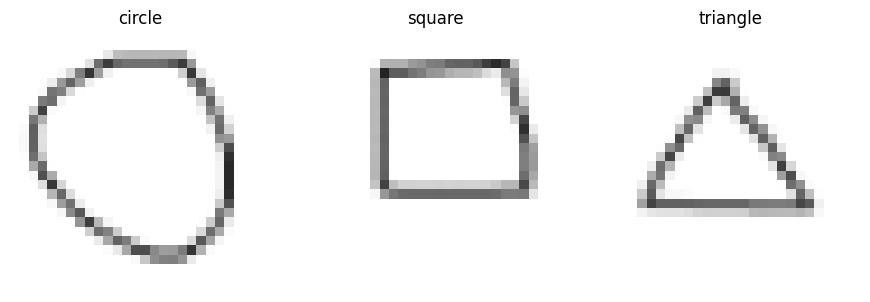

In [2]:
# prikaz primerov slik iz vsake kategorije
fig, axes = plt.subplots(1, len(categories), figsize=(9, 3))

for ax, cat in zip(axes, categories):
    idx = labels.index(cat)
    with Image.open(image_paths[idx]) as img:
        ax.imshow(img)
    ax.set_title(cat)
    ax.axis('off')

plt.tight_layout()
plt.show()

In [3]:
# preverjanje dimenzij slik in stevila primerov po razredih
sizes = set()
for path in image_paths:
    with Image.open(path) as img:
        sizes.add(img.size)

print('Dimenzije slik:', sizes)
for cat in categories:
    print(f'{cat}: {labels.count(cat)}')

Dimenzije slik: {(28, 28)}
circle: 100
square: 100
triangle: 100


In [4]:
# priprava polja vhodnih podatkov X in oznak y
X = []
for path in image_paths:
    with Image.open(path) as img:
        gray = img.convert('L')
        vector = np.array(gray).flatten()
        X.append(vector)

X = np.array(X)
y = np.array(labels)

print('Oblika X:', X.shape)
print('Oblika y:', y.shape)

Oblika X: (300, 784)
Oblika y: (300,)


In [5]:
# razdelitev podatkov na ucno in testno mnozico
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=4321, shuffle=True, stratify=y
)

In [6]:
# ucenje modela odlocitvenega drevesa
clf = DecisionTreeClassifier(random_state=1234)
clf.fit(X_train, y_train)

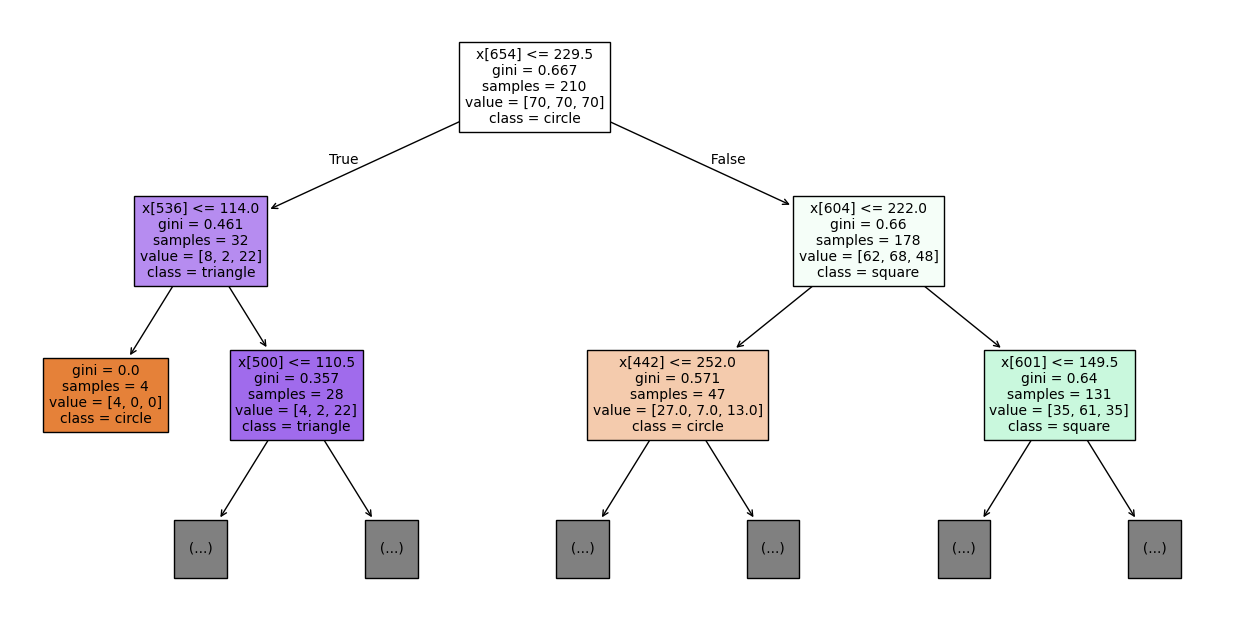

In [7]:
# izris prvih ravni odlocitvenega drevesa
plt.figure(figsize=(16, 8))
plot_tree(clf, max_depth=2, class_names=clf.classes_, filled=True, fontsize=10)
plt.show()

In [8]:
# napovedi in izracun metrik na testni mnozici
y_pred = clf.predict(X_test)

print('Tocnost (Accuracy):', accuracy_score(y_test, y_pred))
print('Utezena F1-vrednost (Weighted F1-score):', f1_score(y_test, y_pred, average='weighted'))
print('Utezena preciznost (Weighted Precision):', precision_score(y_test, y_pred, average='weighted'))
print('Utezen priklic (Weighted Recall):', recall_score(y_test, y_pred, average='weighted'))

Tocnost (Accuracy): 0.43333333333333335
Utezena F1-vrednost (Weighted F1-score): 0.4354066985645933
Utezena preciznost (Weighted Precision): 0.4413580246913581
Utezen priklic (Weighted Recall): 0.43333333333333335


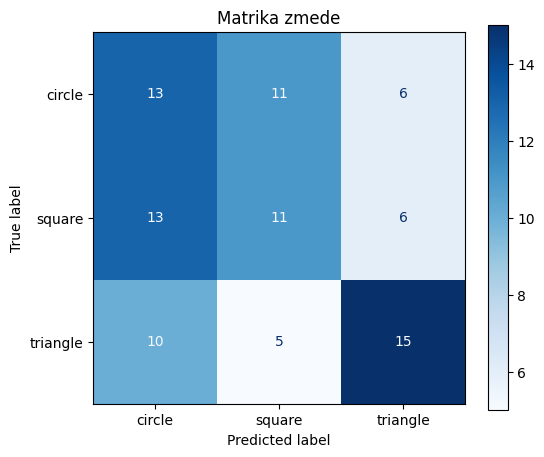

In [9]:
# izracun in graficni prikaz matrike zmede
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=categories, cmap='Blues', ax=ax)
plt.title('Matrika zmede')
plt.show()

# Interpretacija

Model odlocitvenega drevesa na testni mnozici dosega tocnost 43,3 %, utezeno F1-vrednost 0,435, utezeno preciznost 0,441 in utezen priklic 0,433. Rezultati so nekoliko boljsi od nakljucnega ugibanja (33,3 %), vendar se vedno relativno nizki, kar je pricakovano pri gradnji enega odlocitvenega drevesa neposredno na surovih vrednostih slikovnih pik brez predhodne obdelave (centriranje oblik, glajenje suma ali luscenje znacilk).

Iz matrike zmede je razvidno, da model najpogosteje napacno klasificira razred kvadrat (square), saj je pravilno napovedal le 11 od 30 testnih primerov (13 jih je zamenjal za krog in 6 za trikotnik). Prav tako model pogosto zamenjuje kroge za kvadrate (11 krogov je napovedal kot kvadrat). Najbolj zanesljivo model prepoznava razred trikotnik (triangle), kjer je pravilno prepoznal 15 od 30 primerov.

In [10]:
# ucenje knn modelov z razlicnimi k in primerjalna tabela z odlocitvenim drevesom
rezultati = [{
    'Model': 'Decision Tree',
    'Accuracy': accuracy_score(y_test, y_pred),
    'Weighted F1': f1_score(y_test, y_pred, average='weighted'),
    'Weighted Precision': precision_score(y_test, y_pred, average='weighted'),
    'Weighted Recall': recall_score(y_test, y_pred, average='weighted')
}]

for k in [3, 5, 10]:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    p = knn.predict(X_test)
    rezultati.append({
        'Model': f'KNN (k={k})',
        'Accuracy': accuracy_score(y_test, p),
        'Weighted F1': f1_score(y_test, p, average='weighted'),
        'Weighted Precision': precision_score(y_test, p, average='weighted'),
        'Weighted Recall': recall_score(y_test, p, average='weighted')
    })

tabela = pd.DataFrame(rezultati)
tabela

,Model,Accuracy,Weighted F1,Weighted Precision,Weighted Recall
0,Decision Tree,0.433333,0.435407,0.441358,0.433333
1,KNN (k=3),0.533333,0.507143,0.575000,0.533333
2,KNN (k=5),0.500000,0.472096,0.569319,0.500000
3,KNN (k=10),0.522222,0.494117,0.586335,0.522222


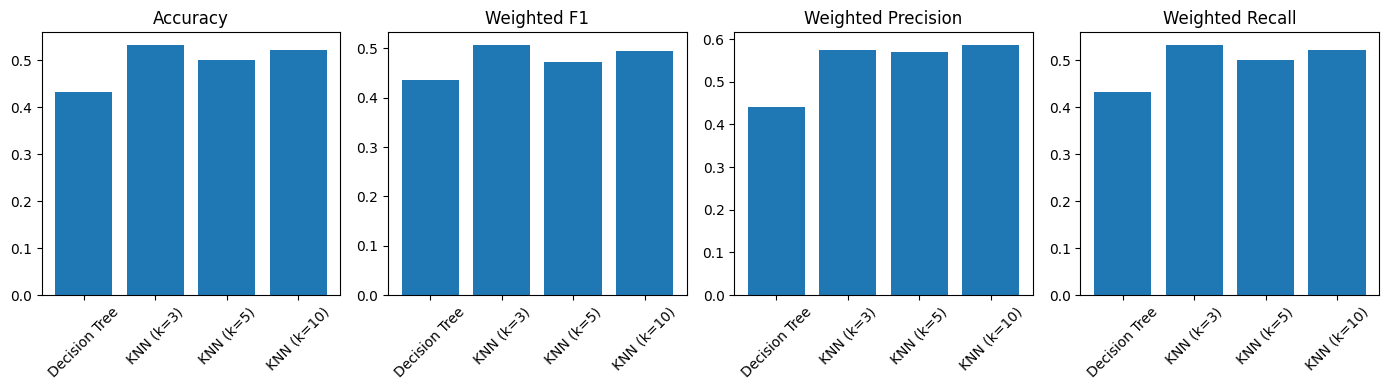

In [11]:
# graficna primerjava rezultatov z locenimi stolpicnimi grafi
plt.figure(figsize=(14, 4))

plt.subplot(1, 4, 1)
plt.bar(tabela['Model'], tabela['Accuracy'])
plt.title('Accuracy')
plt.xticks(rotation=45)

plt.subplot(1, 4, 2)
plt.bar(tabela['Model'], tabela['Weighted F1'])
plt.title('Weighted F1')
plt.xticks(rotation=45)

plt.subplot(1, 4, 3)
plt.bar(tabela['Model'], tabela['Weighted Precision'])
plt.title('Weighted Precision')
plt.xticks(rotation=45)

plt.subplot(1, 4, 4)
plt.bar(tabela['Model'], tabela['Weighted Recall'])
plt.title('Weighted Recall')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# Komentar dodatnega dela

Vsi trije modeli KNN (k=3, k=5 in k=10) dosegajo obcutno boljse rezultate kot odlocitveno drevo na vseh metrikah. Točnost KNN modelov se giblje med 50,0 % in 53,3 % (najvisja pri k=3 z 53,3 %), medtem ko odlocitveno drevo dosega le 43,3 %. Tudi preciznost je pri vseh KNN modelih precej visja (okoli 57-58 % v primerjavi s 44,1 % pri drevesu).

Razlog za boljso uspesnost algoritma KNN je v tem, da KNN pri primerjavi dveh slik uposteva celoten vektor slikovnih pik prek evklidske razdalje (globalna podobnost celotne slike), medtem ko odlocitveno drevo izvaja pravokotne razcepe na podlagi posameznih pikslov, kar pri necentriranih slikah hitro privede do prekomernega prilagajanja (overfittinga) na specificnih pikslih ucnih primerov.

Glede vpliva parametra k: pri manjšem k (k=3) model dobro zajame lokalne vzorce in doseze najvisjo tocnost, vendar je nekoliko bolj obcutljiv na posamezne atipicne slike (sum). Pri vecjih k (k=5 in k=10) pride do vecjega glajenja odlocitvene meje, pri cemer lahko vecje stevilo sosedov zamegli razlike med podobnimi liki (predvsem med krogi in kvadrati), zato se tocnost nekoliko zmanjsa (50,0 % pri k=5 in 52,2 % pri k=10).